### Data dictionary

Source: `bank-names.txt` (UCI Bank Marketing). One row = one client contacted by phone.
45,211 rows, 17 columns, no empty cells.

| # | Column | Meaning | Type | Values / range | Notes |
|---|---|---|---|---|---|
| 1 | `age` | Age of the client | Numeric | 18 – 95 | Median 39 |
| 2 | `job` | Type of job | Categorical | 12 values | 288 "unknown" |
| 3 | `marital` | Marital status | Categorical | married, single, divorced | "divorced" also means widowed |
| 4 | `education` | Education level | Categorical | primary, secondary, tertiary, unknown | 1,857 "unknown" |
| 5 | `default` | Has credit in default? | Binary | yes / no | 98% "no": little information |
| 6 | `balance` | Average yearly balance (EUR) | Numeric | −8,019 – 102,127 | Median 448: very skewed |
| 7 | `housing` | Has a housing loan? | Binary | yes / no | |
| 8 | `loan` | Has a personal loan? | Binary | yes / no | |
| 9 | `contact` | How the client was contacted | Categorical | cellular, telephone, unknown | 13,020 "unknown" |
| 10 | `day` | Day of the month of the last contact | Numeric | 1 – 31 | A calendar day, not a quantity |
| 11 | `month` | Month of the last contact | Categorical | jan – dec | No year in the data |
| 12 | `duration` | Length of the last call (seconds) | Numeric | 0 – 4,918 | Known only after the call: leakage, removed |
| 13 | `campaign` | Calls to this client in this campaign | Numeric | 1 – 63 | Median 2 |
| 14 | `pdays` | Days since the last contact in a previous campaign | Numeric | −1 – 871 | −1 = never contacted before |
| 15 | `previous` | Calls to this client before this campaign | Numeric | 0 – 275 | 275 looks like an error |
| 16 | `poutcome` | Result of the previous campaign | Categorical | success, failure, other, unknown | 36,959 "unknown" |
| 17 | `y` | **Target**: did the client subscribe a term deposit? | Binary | yes / no | 11.7% yes: unbalanced |

## 1. Data loading and integrity

**Observations**
- No empty cells, but "unknown" is a missing value in disguise: `poutcome` 36959 rows, `contact` 13,020, `education` 1,857, `job` 288.
- `pdays` = -1 means "never contacted before". It is a code, not a number.
- `duration` is known only after the call. I will not use it to predict. This is data leakage.
- No duplicate rows.
- `default`, `housing`, `loan` and `y` have only 2 values (yes/no).
- `day` is stored as a number, but it is a day of the month, not a quantity.

In [6]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/bank-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")

print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
df.info()

# One row per column: type, empty cells, "unknown" values, distinct values
integrity = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "empty": df.isna().sum(),
    "unknown": (df == "unknown").sum(),
    "distinct": df.nunique(),
})
integrity["unknown_%"] = (integrity["unknown"] / len(df) * 100).round(1)
integrity

Rows and columns: (45211, 17)
Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,type,empty,unknown,distinct,unknown_%
age,int64,0,0,77,0.0
job,str,0,288,12,0.6
marital,str,0,0,3,0.0
education,str,0,1857,4,4.1
default,str,0,0,2,0.0
balance,int64,0,0,7168,0.0
housing,str,0,0,2,0.0
loan,str,0,0,2,0.0
contact,str,0,13020,3,28.8
day,int64,0,0,31,0.0


In [7]:
display(df.head())
display(df.describe().T)
display(df.describe(exclude="number").T)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


## Data quality checks

**Data quality**
- No empty cells, but "unknown" is a missing value in disguise: `poutcome` 36959 rows, `contact` 13,020, `education` 1,857, `job` 288.
- `pdays` = -1 means "never contacted before". It is a code, not a number.
- One row was removed where `previous = 275` because it is probably an error, as this value is too high compared to the average."
- `duration` is known only after the call. I will not use it to predict. This is data leakage.
- `default`, `housing`, `loan` and `y` have only 2 values (yes/no).
- The classes are unbalanced because only 11.7% of the clients said 'yes'.

In [8]:
never_contacted = (df["pdays"] == -1).sum()
print("pdays = -1:", never_contacted, f"({never_contacted / len(df) * 100:.1f}%)")

highest_previous = df["previous"].sort_values(ascending=False).head(5)
print("Highest 'previous':", highest_previous.tolist())

print(df.groupby("y")["duration"].median())

print("\nTarget:")
print(df["y"].value_counts(normalize=True).round(3))

pdays = -1: 36954 (81.7%)
Highest 'previous': [275, 58, 55, 51, 41]
y
no     164.0
yes    426.0
Name: duration, dtype: float64

Target:
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


## Cleaning

**Cleaning decisions**
- There are many unknown rows, and deleting them would remove too much data.
- A new column `contacted_before` was created because pdays uses the value -1 as a special code for `never contacted before`.
- One row was removed where `previous = 275` because it is probably an error, as this value is too high compared to the average."
- `duration` was removed because it is only known after the call, so it has no predictive value and causes data leakage

In [9]:
clean = df.copy()

clean["contacted_before"] = clean["pdays"] != -1
clean = clean[clean["previous"] != 275]
clean["y"] = clean["y"] == "yes"
clean = clean.drop(columns=["duration"])

display(len(df))
display(len(clean))

percentage = clean["y"].mean() * 100
print(f"Clients who said yes: {percentage:.1f}%")

45211

45210

Clients who said yes: 11.7%


## Findings

poutcome
failure    12.6
other      16.7
success    64.7
unknown     9.2
Name: y, dtype: float64
poutcome
unknown    36959
failure     4901
other       1839
success     1511
Name: count, dtype: int64


Text(0.5, 0, 'Clients who said yes (%)')

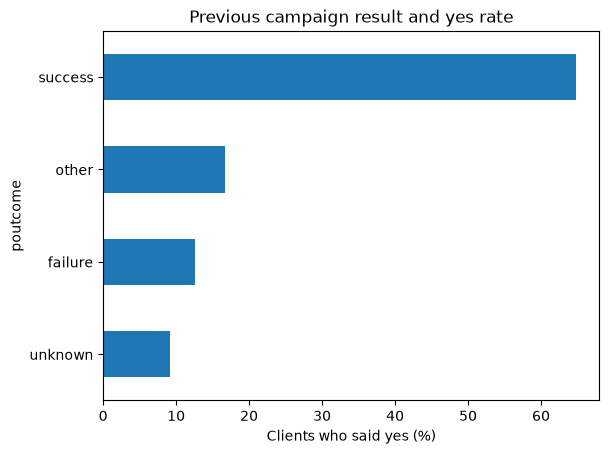

In [10]:
rate = clean.groupby("poutcome")["y"].mean() * 100
print(rate.round(1))
print(clean["poutcome"].value_counts())

ax = rate.sort_values().plot(kind="barh", title="Previous campaign result and yes rate")
ax.set_xlabel("Clients who said yes (%)")

job
admin.           12.2
blue-collar       7.3
entrepreneur      8.3
housemaid         8.8
management       13.8
retired          22.8
self-employed    11.8
services          8.9
student          28.7
technician       11.1
unemployed       15.5
unknown          11.8
Name: y, dtype: float64
job
blue-collar      9732
management       9457
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


Text(0.5, 0, 'Clients who said yes (%)')

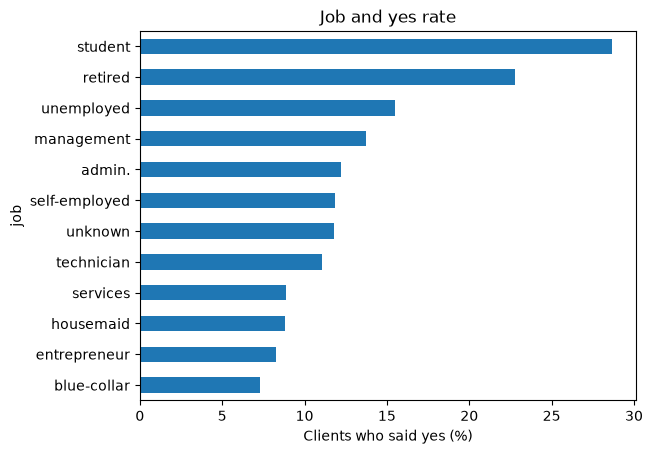

In [11]:
rate = clean.groupby("job")["y"].mean() * 100
print(rate.round(1))
print(clean["job"].value_counts())

ax = rate.sort_values().plot(kind="barh", title="Job and yes rate")
ax.set_xlabel("Clients who said yes (%)")

calls
1      14.6
2      11.2
3      11.2
4-5     8.6
6+      5.8
Name: y, dtype: float64
calls
1      17544
2      12504
3       5521
4-5     5286
6+      4355
Name: count, dtype: int64


Text(0, 0.5, 'Clients who said yes (%)')

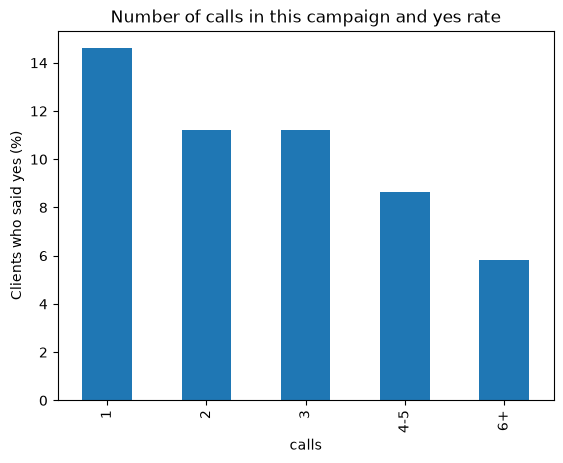

In [12]:
# Group the number of calls into bands: 1, 2, 3, 4-5, 6 or more
clean["calls"] = pd.cut(clean["campaign"], bins=[0, 1, 2, 3, 5, 100],
                        labels=["1", "2", "3", "4-5", "6+"])

rate = clean.groupby("calls")["y"].mean() * 100
print(rate.round(1))
print(clean["calls"].value_counts())

ax = rate.plot(kind="bar", title="Number of calls in this campaign and yes rate")
ax.set_ylabel("Clients who said yes (%)")

Text(0.5, 0, 'Age')

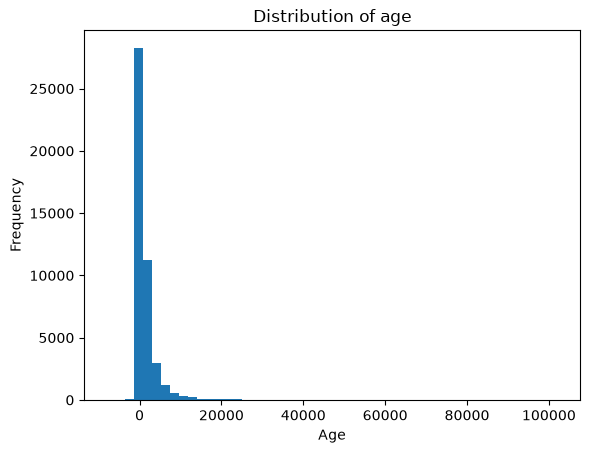

In [ ]:
ax = clean["balance"].plot(kind="hist", bins=50, title="Distribution of balance")
ax.set_xlabel("Balance (EUR)")

Text(0.5, 0, 'Age')

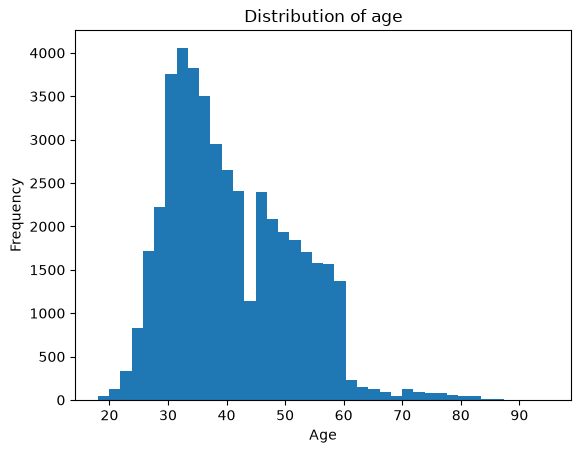

In [16]:
ax = clean["age"].plot(kind="hist", bins=40, title="Distribution of age")
ax.set_xlabel("Age")

In [17]:
numbers = clean[["age", "balance", "day", "campaign", "previous", "y"]].astype(float)
print(numbers.corr()["y"].round(3))

age         0.025
balance     0.053
day        -0.028
campaign   -0.073
previous    0.114
y           1.000
Name: y, dtype: float64
